| Symbol | Description |
|:------:|:------------|
| $J$ | Set of decision points |
| $A_j$ | Set of legal actions at decision point $j \in J$ |
| $K$ | Set of observation points |
| $S_k$ | Set of possible signals at observation point $k \in K$ |
| $\rho$ | Transition function, defined below |
| $\Sigma$ | Set of sequences, defined as $\Sigma \coloneqq \{(j,a) : j \in J,\ a \in A_j\}$ |
| $p_j$ | Parent sequence of decision point $j \in J$: the last sequence (decision point–action pair) on the path from the root of the TFDP to $j$. If the agent does not act before $j$, then $p_j = \varnothing$. |

**Transition function $\rho$:**

- Given $j \in J$ and $a \in A_j$, $\rho(j,a)$ returns the next decision or observation point $v \in J \cup K$ reached after selecting action $a$, or $\bot$ if the decision process ends.
- Given $k \in K$ and $s \in S_k$, $\rho(k,s)$ returns the next decision or observation point $v \in J \cup K$ reached after observing signal $s$, or $\bot$ if the decision process ends.

### Algorithm 1: CFR regret minimizer

**Data:** $R_j$, a regret minimizer for $\Delta(A_j)$, for each decision point $j \in \mathcal{J}$ of the TFDP.

**Function `NextStrategy()`**

*Step 1: Ask each $R_j$ for its next strategy local at each decision point.*

- For each decision point $j \in \mathcal{J}$:
  - $b_j^{(t)} \in \Delta(A_j) \leftarrow R_j.\mathrm{NextStrategy}()$

*Step 2: Construct the sequence-form representation of the strategy that plays according to the distribution $b_j^{(t)}$ at each decision point $j \in \mathcal{J}$.*

- Initialize $x^{(t)} \leftarrow 0 \in \mathbb{R}^{\Sigma}$.
- For each decision point $j \in \mathcal{J}$ in **top-down traversal order** in the TFDP:
  - For each action $a \in A_j$:
    - If $p_j = \varnothing$:
      $$
      x^{(t)}[ja] \leftarrow b_j^{(t)}[a]
      $$
    - Otherwise:
      $$
      x^{(t)}[ja] \leftarrow x^{(t)}[p_j] \cdot b_j^{(t)}[a]
      $$

The vector $x^{(t)}$ is a valid sequence-form strategy: it satisfies the sequence-form consistency constraints (Section L7.3.3). In symbols, $x^{(t)} \in Q$.

- Return $x^{(t)}$.

---

**Function $\mathrm{ObserveUtility}(g^{(t)} \in \mathbb{R}^{|\Sigma|})$**

*Step 1: Compute the expected utility for each subtree rooted at each node $v \in \mathcal{J} \cup \mathcal{K}$.*

- Initialize $V^{(t)}$ as an empty dictionary. Eventually, it maps keys in $\mathcal{J} \cup \mathcal{K} \cup \{\bot\}$ to real numbers.
- Set $V^{(t)}[\bot] \leftarrow 0$.
- For each node $v \in \mathcal{J} \cup \mathcal{K}$ in **bottom-up traversal order** in the TFDP:
  - If $v \in \mathcal{J}$:
    - Let $j \leftarrow v$.
    - Set
      $$
      V^{(t)}[j] \leftarrow
      \sum_{a \in A_j}
      b_j^{(t)}[a] \cdot
      \left(g^{(t)}[ja] + V^{(t)}[\rho(j,a)]\right).
      $$
  - Otherwise:
    - Let $k \leftarrow v$.
    - Set
      $$
      V^{(t)}[k] \leftarrow
      \sum_{s \in S_k} V^{(t)}[\rho(k,s)].
      $$

*Step 2: At each decision point $j \in \mathcal{J}$, construct a local utility vector $g_j^{(t)}$, called counterfactual utility.*

- For each decision point $j \in \mathcal{J}$:
  - Initialize $g_j^{(t)} \leftarrow 0 \in \mathbb{R}^{A_j}$.
  - For each action $a \in A_j$:
    $$
    g_j^{(t)}[a] \leftarrow
    g^{(t)}[ja] + V^{(t)}[\rho(j,a)].
    $$
  - Call $R_j.\mathrm{ObserveUtility}(g_j^{(t)})$.

In [1]:
from dataclasses import dataclass
import numpy as np

### Data structures

Create nodes with `DecisionPoint(actions=[...])` and
`ObservationPoint(signals=[...])`. Labels are dictionary keys, such as strings or
integers. Connect each node's `children[label]` to its successor, using `None` for
terminal outcomes. Use `node.metadata` for any extra information.

Supply a complete tree with no cycles or shared nodes, then construct
`process = TreeFormDecisionProcess(root)` and `cfr = CFR(process)`. Keep the tree
and label order fixed afterward. The process describes one player's decisions
and fills in each decision point's `parent` sequence, carrying it through
observation points. A parent of `None` means the player has not acted yet.

- `process.top_down` and `process.bottom_up` give the traversal orders.
- `process.sequence_index[Sequence(j, a)]` indexes `(j, a)` in the global strategy
  `x` and utility vector `g`.
- `process.action_index[j][a]` indexes `a` in local strategy and utility vectors.
- `Sequence(j, a)` stores a decision point and an action. `frozen=True`
  prevents changing its fields, allowing sequences to be dictionary keys.
  Each node object is a distinct dictionary key.

Each round, call `cfr.NextStrategy()` to obtain a sequence-form strategy, then
`cfr.ObserveUtility(g)` with a NumPy utility vector in `process.sequences` order.
Regret matching uses positive cumulative regrets as action weights, choosing
uniformly when none are positive. CFR uses the process's shared operations:

- `sequence_strategy(local_strategies)` converts local distributions to a global vector.
- `local_strategy(x, j)` recovers a distribution at a decision with positive own reach.
- `evaluate(g, decision_value)` computes subtree values and local action utilities.
  The supplied function `decision_value(j, utility)` tells it how to combine the
  action utilities: CFR takes their expected value under the saved local strategy;
  a best response takes their maximum. The short `lambda` expressions below
  define these functions inline.

CFR evaluates the tree with the current round's saved strategies, then passes the
resulting local utilities to the regret minimizers.

In [2]:
class DecisionPoint:
    def __init__(self, actions: list):
        self.actions = actions
        self.children: dict = {}
        self.parent: Sequence | None = None  # Filled by the process.
        self.metadata: dict = {}


class ObservationPoint:
    def __init__(self, signals: list):
        self.signals = signals
        self.children: dict = {}
        self.metadata: dict = {}


@dataclass(frozen=True)
class Sequence:
    j: DecisionPoint
    a: object


def transition_function(v, label):
    """Return the child after an action or signal; None means termination."""
    return v.children[label]


class TreeFormDecisionProcess:
    """One player's decision tree, with parent sequences and vector indices."""

    def __init__(self, root):
        self.root = root
        self.top_down = []
        self.decision_points: list[DecisionPoint] = []
        self.observation_points: list[ObservationPoint] = []

        def visit(v, parent):
            if v is None:
                return
            self.top_down.append(v)
            if isinstance(v, DecisionPoint):
                v.parent = parent
                self.decision_points.append(v)
                for a in v.actions:
                    visit(transition_function(v, a), Sequence(v, a))
            else:
                self.observation_points.append(v)
                for s in v.signals:
                    visit(transition_function(v, s), parent)

        visit(root, None)
        self.bottom_up = self.top_down[::-1]
        # x[i] and g[i] refer to self.sequences[i].
        self.sequences = [Sequence(j, a) for j in self.decision_points for a in j.actions]
        self.sequence_index = {seq: i for i, seq in enumerate(self.sequences)}
        self.action_index = {
            j: {a: i for i, a in enumerate(j.actions)} for j in self.decision_points
        }

    def sequence_strategy(self, local_strategies: dict) -> np.ndarray:
        """Convert local action distributions to sequence-form probabilities."""
        x = np.zeros(len(self.sequences))
        for j in self.decision_points:
            reach = 1 if j.parent is None else x[self.sequence_index[j.parent]]
            for a, i in self.action_index[j].items():
                x[self.sequence_index[Sequence(j, a)]] = reach * local_strategies[j][i]
        return x

    def local_strategy(self, x: np.ndarray, j: DecisionPoint) -> np.ndarray:
        """Recover a local distribution at a decision with positive own reach."""
        weights = np.array([x[self.sequence_index[Sequence(j, a)]] for a in j.actions])
        return weights / weights.sum()

    def evaluate(self, g: np.ndarray, decision_value):
        """Compute subtree and action utilities using decision_value(j, utility)."""
        V = {None: 0}
        utilities = {}
        for v in self.bottom_up:
            if isinstance(v, DecisionPoint):
                utilities[v] = np.array([
                    g[self.sequence_index[Sequence(v, a)]] + V[transition_function(v, a)]
                    for a in v.actions
                ])
                V[v] = decision_value(v, utilities[v])
            else:
                V[v] = sum(V[transition_function(v, s)] for s in v.signals)
        return V, utilities

In [3]:
class RegretMatching:
    """A local regret minimizer at one decision point."""

    def __init__(self, num_actions: int):
        self.regret_sum = np.zeros(num_actions)
        self.last_strategy = None

    def NextStrategy(self) -> np.ndarray:
        """Return and save a distribution in the decision point's action order."""
        positive_regrets = np.maximum(self.regret_sum, 0)
        total = positive_regrets.sum()
        if total > 0:
            self.last_strategy = positive_regrets / total
        else:
            self.last_strategy = np.ones(len(self.regret_sum)) / len(self.regret_sum)
        return self.last_strategy

    def ObserveUtility(self, utility: np.ndarray) -> None:
        """Update regrets using local utilities and the last local strategy."""
        self.regret_sum += utility - self.last_strategy @ utility


class CFR:
    """One local regret minimizer per decision point."""

    def __init__(self, process: TreeFormDecisionProcess):
        self.process = process
        self.local_learners = {
            j: RegretMatching(len(j.actions)) for j in process.decision_points
        }
        # Save each round's b_j for ObserveUtility.
        self.local_strategies = {}
        self.last_strategy = None

    def NextStrategy(self) -> np.ndarray:
        """Save local strategies and return x in process.sequences order."""
        self.local_strategies = {
            j: learner.NextStrategy() for j, learner in self.local_learners.items()
        }
        self.last_strategy = self.process.sequence_strategy(self.local_strategies)
        return self.last_strategy

    def ObserveUtility(self, g: np.ndarray) -> None:
        """Use this round's saved strategies and sequence utilities to update regrets."""
        _, utilities = self.process.evaluate(
            g, lambda j, utility: self.local_strategies[j] @ utility
        )
        for j, utility in utilities.items():
            self.local_learners[j].ObserveUtility(utility)

### Kuhn poker: constructing the decision processes

Each player antes one chip and privately receives one of `J < Q < K`, without
replacement. Player 1 can check or bet one chip; after a check, Player 2 can check
or bet. Facing a bet, a player can fold or call. A fold or an unbet showdown is
worth one net chip to the winner; a called bet is worth two.


We now construct the nodes and their connections directly, using the classes
above. Actions and signals are string labels. Each decision point records only
own card and public history, so neither player observes the opponent's card.
A `None` child means this player has no further decisions, even if the opponent
still has a final move to make.

Player 1: observe a card, then check or bet. After checking, observe the
opponent's action; if the opponent bets, choose whether to fold or call. The loop
below creates this same small tree for each of the three possible private cards.

In [4]:
cards = ['J', 'Q', 'K']
opening_actions = ['check', 'bet']
responses = ['fold', 'call']

p1_deal = ObservationPoint(signals=cards)
p1_open, p1_reply = {}, {}

for card in cards:
    p1_open[card] = DecisionPoint(actions=opening_actions)
    p1_reply[card] = DecisionPoint(actions=responses)
    opponent_action = ObservationPoint(signals=opening_actions)

    p1_deal.children[card] = p1_open[card]
    p1_open[card].children = {'check': opponent_action, 'bet': None}
    opponent_action.children = {'check': None, 'bet': p1_reply[card]}
    p1_reply[card].children = {'fold': None, 'call': None}

    p1_open[card].metadata = {'card': card, 'history': ()}
    p1_reply[card].metadata = {'card': card, 'history': ('check', 'bet')}

p1 = TreeFormDecisionProcess(p1_deal)

**Player 2:** observe a card and Player 1's opening action. After a check,
choose check or bet; after a bet, choose fold or call. Player 2 has no further
decisions after either choice.

In [5]:
p2_deal = ObservationPoint(signals=cards)
p2_after_check, p2_after_bet = {}, {}

for card in cards:
    opponent_action = ObservationPoint(signals=opening_actions)
    p2_after_check[card] = DecisionPoint(actions=opening_actions)
    p2_after_bet[card] = DecisionPoint(actions=responses)

    p2_deal.children[card] = opponent_action
    opponent_action.children = {'check': p2_after_check[card], 'bet': p2_after_bet[card]}
    p2_after_check[card].children = {'check': None, 'bet': None}
    p2_after_bet[card].children = {'fold': None, 'call': None}

    p2_after_check[card].metadata = {'card': card, 'history': ('check',)}
    p2_after_bet[card].metadata = {'card': card, 'history': ('bet',)}

p2 = TreeFormDecisionProcess(p2_deal)

### Sequences and payoffs

The processes have filled in each decision point's parent and enumerated its
Sequence(j, a) objects. For example, Sequence(p1_open['J'], 'check') represents
Player 1 checking with a Jack; it is the parent of p1_reply['J'].

For each deal, the table below explicitly pairs the players' last sequences at
each of the five terminal outcomes. The sequence weights already include earlier
own actions, so a final fold or call by Player 1 includes their earlier check.
Each ordered deal has probability $1/6$.

The resulting matrix satisfies $u_1(x,y) = x^T A y$. We will pass $Ay$ to Player 1's
CFR learner and $-A^T x$ to Player 2's learner.

In [6]:
from itertools import permutations

A = np.zeros((len(p1.sequences), len(p2.sequences)))
deals = list(permutations(cards, 2))

for card1, card2 in deals:
    win = 1 if cards.index(card1) > cards.index(card2) else -1
    first, reply = p1_open[card1], p1_reply[card1]
    after_check, after_bet = p2_after_check[card2], p2_after_bet[card2]

    # (Player 1's last sequence, Player 2's last sequence, Player 1's net payoff)
    outcomes = [
        (Sequence(first, 'check'), Sequence(after_check, 'check'), win),
        (Sequence(first, 'bet'), Sequence(after_bet, 'fold'), 1),
        (Sequence(first, 'bet'), Sequence(after_bet, 'call'), 2 * win),
        (Sequence(reply, 'fold'), Sequence(after_check, 'bet'), -1),
        (Sequence(reply, 'call'), Sequence(after_check, 'bet'), 2 * win),
    ]
    for seq1, seq2, payoff in outcomes:
        A[p1.sequence_index[seq1], p2.sequence_index[seq2]] += payoff / len(deals)

### Measuring convergence

Average the **sequence-form vectors** across iterations. This automatically
weights later decisions by the player's own earlier action probabilities; an
unweighted average of local action distributions would be incorrect.

An exact best response uses the same bottom-up tree walk as CFR, replacing the
weighted average at each decision point with a maximum. Opponent and chance
probabilities are already in the utility vector, so observation values still sum.
For the averaged strategies $(\bar x, \bar y)$, define

$$
L = \min_y \bar x^T A y, \qquad U = \max_x x^T A \bar y,
\qquad \text{exploitability} = \frac{U-L}{2}.
$$

$L$ and $U$ bracket the equilibrium value. Here exploitability is the average of
the two players' gains from a unilateral best response; zero means equilibrium.
The average profile's payoff alone is not an equilibrium certificate.

Each iteration below updates both learners against the same pair of current
strategies. All deals are included exactly, so this run is deterministic.

In [7]:
def best_response_value(process: TreeFormDecisionProcess, g: np.ndarray) -> float:
    """Maximize the sequence-form utility g over this player's decision tree."""
    V, _ = process.evaluate(g, lambda j, utility: utility.max())
    return V[process.root]


iterations = 50_000

In [8]:
cfr1, cfr2 = CFR(p1), CFR(p2)
x_sum = np.zeros(len(p1.sequences))
y_sum = np.zeros(len(p2.sequences))
checkpoints = set(np.geomspace(1, iterations, 160).astype(int))
history = []

for t in range(1, iterations + 1):
    x, y = cfr1.NextStrategy(), cfr2.NextStrategy()
    x_sum += x
    y_sum += y
    cfr1.ObserveUtility(A @ y)
    cfr2.ObserveUtility(-A.T @ x)

    if t in checkpoints:
        x_average, y_average = x_sum / t, y_sum / t
        lower = -best_response_value(p2, -A.T @ x_average)
        upper = best_response_value(p1, A @ y_average)
        value = x_average @ A @ y_average
        history.append((t, value, lower, upper))

x_average, y_average = x_sum / iterations, y_sum / iterations
history = np.array(history)
t, value, lower, upper = history[-1]
print(f"{int(t):,} CFR iterations; payoff matrix shape: {A.shape}")
print(f"Average profile payoff to Player 1: {value:.6f} chips/hand")
print(f"Best-response bounds: [{lower:.6f}, {upper:.6f}]")
print(f"Exploitability: {(upper - lower) / 2:.6f} chips/hand")

50,000 CFR iterations; payoff matrix shape: (12, 12)
Average profile payoff to Player 1: -0.055556 chips/hand
Best-response bounds: [-0.056573, -0.054575]
Exploitability: 0.000999 chips/hand


### Convergence graphs

The left plot measures how much either player can gain by deviating. The right
plot shows the averaged profile's payoff and its best-response bounds approaching
$-1/18$ chips per hand, the equilibrium value used in
[OpenSpiel's Kuhn poker checks](https://github.com/google-deepmind/open_spiel/blob/master/open_spiel/python/algorithms/cfr_test.py).

The plotted strategies are averages over all iterations up to each checkpoint.
The current strategy need not converge, and the curves need not be monotone.
The cell saves PNG and PDF copies in the notebook's working directory.

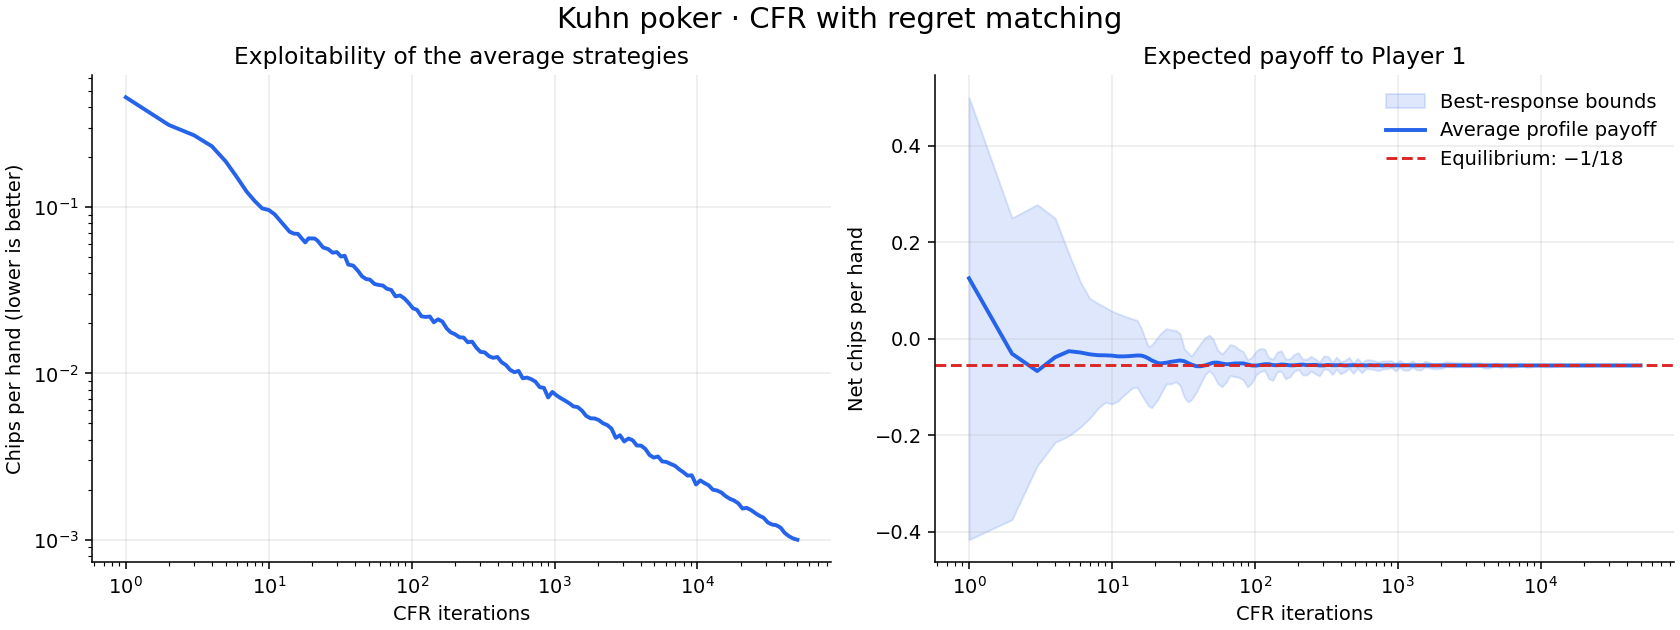

In [9]:
import matplotlib.pyplot as plt

steps, values, lower, upper = history.T
exploitability = (upper - lower) / 2
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')

axes[0].loglog(steps, exploitability, color='#2563eb', linewidth=2)
axes[0].set_title('Exploitability of the average strategies')
axes[0].set_ylabel('Chips per hand (lower is better)')

axes[1].fill_between(steps, lower, upper, color='#2563eb', alpha=0.15,
                     label='Best-response bounds')
axes[1].semilogx(steps, values, color='#2563eb', linewidth=2,
                 label='Average profile payoff')
axes[1].axhline(-1 / 18, color='#dc2626', linestyle='--', label='Equilibrium: −1/18')
axes[1].set_title('Expected payoff to Player 1')
axes[1].set_ylabel('Net chips per hand')
axes[1].legend(frameon=False)

for ax in axes:
    ax.set_xlabel('CFR iterations')
    ax.grid(True, which='major', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Kuhn poker · CFR with regret matching', fontsize=15)
fig.savefig('kuhn_convergence.png', dpi=180)
fig.savefig('kuhn_convergence.pdf')
plt.show()

### Inspecting the learned strategy

Normalize each decision point's average sequence weights to recover its
conditional action probabilities. Every decision has positive average own reach
here because the first iteration plays uniformly. Kuhn poker has multiple
optimal strategies for Player 1, so exploitability is a more useful convergence
check than matching a particular table of action probabilities.

In [10]:
for player, (process, average) in enumerate(zip([p1, p2], [x_average, y_average])):
    print(f"\nPlayer {player + 1}")
    for j in process.decision_points:
        probabilities = process.local_strategy(average, j)
        context = ' → '.join(j.metadata['history']) or 'start'
        actions = ', '.join(f"{a}: {p:.3f}" for a, p in zip(j.actions, probabilities))
        print(f"  {j.metadata['card']} | {context:12} | {actions}")


Player 1
  J | start        | check: 0.793, bet: 0.207
  J | check → bet  | fold: 1.000, call: 0.000
  Q | start        | check: 1.000, bet: 0.000
  Q | check → bet  | fold: 0.454, call: 0.546
  K | start        | check: 0.379, bet: 0.621
  K | check → bet  | fold: 0.000, call: 1.000

Player 2
  J | check        | check: 0.667, bet: 0.333
  J | bet          | fold: 1.000, call: 0.000
  Q | check        | check: 1.000, bet: 0.000
  Q | bet          | fold: 0.662, call: 0.338
  K | check        | check: 0.000, bet: 1.000
  K | bet          | fold: 0.000, call: 1.000
